# 딥러닝 ② FOCUS ON TRANSFORMER

- RNN의 한계
    - Attention의 등장
    - Attention is All You Need
        - 트랜스포머란?
- Self-Attetion
    - Query, Key, Value
    - Cross-Attention vs. Self-Attention
    - Scaled Dot-Product Attention
- Multi-Head Attention
    - Single-Head Attention VS. Multi-Head Attention
    - Multi-Head Attention 작동 방식
- Transformer 전체 아키텍처
    - 트랜스포머의 전처리 단계
    - Encoder와 Decoder

## <span style="background-color:#fae0f0; color:#c0156d; padding:4px; border-radius:5px;"> 1. 인트로 </span>

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 1.1 RNN의 한계와 어텐션의 등장 </span>

#### 1. **Seq2Seq 복습**
- 입력 시퀀스를 받아 **다른 시퀀스로 변환**하는 모델 구조
  - 입출력 길이가 달라도 OK, 번역/요약/음성 인식 등에 사용
- **Encoder** : LSTM이 단어를 한 개씩 읽고, 문장 전체 의미를 **하나의 Context Vector** 로 압축
- **Context Vector** : 인코더가 만든 문장 요약본, 인코더와 디코더를 잇는 유일한 통로
- **Decoder** : Context Vector를 받아 번역문을 한 단어씩 생성 
  - `<sos>`로 시작 -> 방금 만든 단어를 다시 입력 -> `<eos>`에서 멈춤
- 근데 디코더가 참고할 수 있는 건 **Context Vector 하나뿐**!

#### 2. **Attention의 등장 배경 : Seq2Seq의 병목 현상**
- Context Vector의 크기가 **고정**되어 있어 입력이 5단어든 50단어든 같은 크기에 담아야 함 
  - -> 문장이 길수록 **정보 손실**
- 디코더가 서로 다른 길이의 단어를 만들 때에도 **똑같은 요약본**을 참고 
  - -> 출력 단어마다 필요한 정보를 다르게 반영 불가
- Context Vector는 인코더의 **마지막 hidden state** -> 앞쪽 단어 정보는 희미해짐
- **해결** : 디코더가 단어를 생성할 때마다 **입력 문장 전체를 다시 보고**, 현재 단어와 관련 있는 부분에 집중해 **출력 단어마다 새로운 Context Vector** 생성!

#### 3. **Attention의 정의**
- <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> 현재 시점에서 가장 중요한 부분에 더 높은 가중치를 부여하는 기술 </span>
  - 출력 단어를 생성할 때 입력 문장 속 어떤 단어에 **얼마나 집중할지**를 결정
- **구조 (Seq2Seq + Attention)**
  - 인코더 : 마지막 hidden state 하나가 아니라 **모든 시점의 hidden state를 남겨둠**
  - 디코더의 현재 상태를 인코더의 각 hidden state와 비교해 **관련도 점수** 계산 
    - -> **Softmax**로 합이 1인 비율(어텐션 가중치)로 변환 
    - -> 이 비율로 hidden state를 섞어 **Context Vector** 생성
  - 디코더 상태 + Context Vector -> Dense + Softmax -> 단어 출력

- 기존 Seq2Seq는 원문 정보를 순차적으로 전달받은 결과만 사용, Attention은 **디코더와 인코더의 모든 위치를 직접 비교!**
- **관련 용어**
  - **Hidden state** : RNN/LSTM이 단어를 읽을 때마다 갱신하는, 그 시점까지의 문맥을 담은 벡터
  - **Attention Score** : 디코더의 현재 상태와 인코더 각 단어 사이의 관련도 점수
  - **Attention Weight** : Softmax를 거친 비율, 각 단어를 얼마나 참고할지

#### 4. **Attention의 과정**
1. **입력을 벡터로 변환** : 입력 단어를 숫자 벡터로 변환
2. **단어별 중요도 계산** : 관련도 점수 -> Softmax -> Attention Weight
   - <span style="color:green">ex. student가 3.8점의 관련도 점수 -> Softmax를 거쳐 80% 가중치 = "student에 80% 집중"</span>
3. **중요도에 따른 입력 정보 조합** : 어텐션 가중치만큼 각 단어의 hidden state를 섞어 Context Vector 생성

#### 5. **Attention 메커니즘의 장점**
1. **시간 경과에 대한 유연성 (vs RNN)**
   1. RNN은 멀리 떨어진 단어일수록 정보가 흐려지지만, Attention은 모든 단어를 직접 비교하므로 **거리와 상관없이** 관계 파악
2. **공간에 대한 유연성 (vs CNN)**
   1. CNN은 고정 크기 필터로 주변만 보지만, Attention은 모든 위치를 직접 연결해 **전역적 관계**를 한 번에 학습
3. **병렬화 (vs RNN)** 
   1. 단어 쌍마다 관련도 계산이 서로 독립적이라 **동시에 계산** 가능
   - <span style="color:blue">단, Seq2Seq + Attention에서는 인코더/디코더가 여전히 LSTM이라 **모델 전체의 병렬화는 안 됨** 
     - attention은 RNN의 보조 역할 </span>
- -> 이 장점을 전체에 살린 것 -> **LSTM을 걷어내고 어텐션만 남긴 모델이 Transformer**

#### 6. **정리 : 모델별 한계**
- **RNN** : 장기 의존성 문제 + 병렬화 불가
- **LSTM** : 장기 의존성은 완화했지만 순차 구조는 그대로
- **Seq2Seq + Attention** : 병목 현상은 해결했지만 여전히 RNN 위에서 작동하는 보조 역할

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 1.2 Attention is All You Need </span>

#### 1. **논문 개요**
- **Transformer**를 처음 발표한 논문 (Self-Attention 방식)
- 2017년 NIPS, Google Brain/Research 연구진 8명
- "Attention만 있으면 된다"는 주장 -> **오늘날 LLM의 기반**
- **배경**
  - RNN, LSTM, GRU는 당시 시퀀스 작업의 표준 
  - but n번째 단어를 계산하려면 n-1번째 결과가 먼저 필요한 **순차 구조** 
  - -> 한 문장 안에서 병렬 처리 불가
- **Transformer의 등장** : RNN과 CNN을 **완전히 제거**하고 Self-Attention으로 입력과 출력의 관계를 계산
- <span style="color:blue">**가장 중요한 발견 : Recurrence(순환)와 Convolution(합성곱)은 필수 X**</span>
  - Attention만으로 더 좋은 성능이 가능, 순차 구조를 없앤 덕분에 병렬화로 **빠른 학습**
- **파급효과**
  - **LLM의 탄생** : Transformer의 디코더를 쌓은 **GPT**, 인코더를 쌓은 **BERT**
  - NLP 평정 (번역, 요약, 질의응답 등 자연어 처리 대부분의 표준 구조)
  - 이미지, 음성 등 타 분야로 확장

#### 2. **Transformer란?**
- <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> RNN처럼 순서대로 처리하지 않고 **Attention만으로** 문장 전체의 의미와 구조를 파악해 **한 번에** 처리하는 인코더-디코더 모델 </span>
1. **구조**
   1. 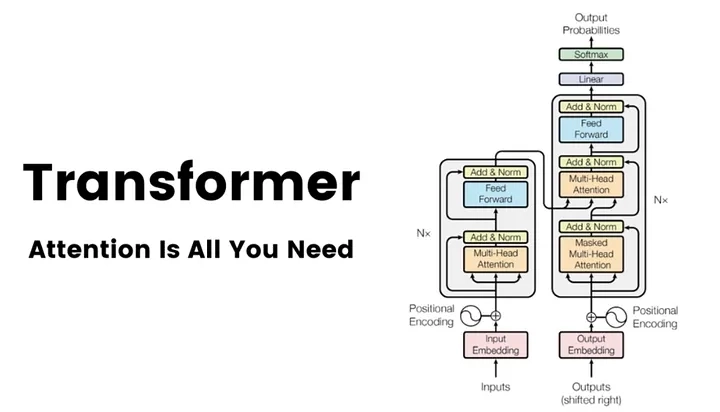
   2. 왼쪽 인코더(입력 문장 이해), 오른쪽 디코더(출력 문장 생성), 층(회색상자) 하나를 **N개 쌓아** 구성

2. **기존과의 차이** : 인코더/디코더 내부를 무엇으로 채웠는가

    | 구분 | Seq2Seq + Attention | Transformer |
    |:----:|:-------------------:|:-----------:|
    | 인코더, 디코더 내부 | LSTM (순차 처리) | Self-Attention |
    | 어텐션의 역할 | RNN을 돕는 보조 | 모델 그 자체 |
    | 어텐션 사용 위치 | 디코더 -> 인코더 1곳 | 인코더 내부, 디코더 내부, 인코더-디코더 사이 3곳 |
    | 단어 순서 정보 | RNN이 순서대로 읽으며 반영 | **Positional Encoding**으로 따로 추가 |
    | 병렬 처리 | 불가 | 가능 |

3. **핵심 기술 3가지**
  - **Self-Attention** : 문장 안의 단어들이 서로를 참고해 한 번에 문맥을 파악
  - **Multi-Head Attention** : Attention을 여러 갈래로 나눠 다양한 관점에서 관계 파악
  - **Positional Encoding** : 각 단어의 위치를 벡터로 만들어 단어 벡터에 더해 **사라진 순서 정보를 보완**

## <span style="background-color:#fae0f0; color:#c0156d; padding:4px; border-radius:5px;"> 2. Self-Attention </span>

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.1 Query, Key, Value </span>

#### 1. **RNN, LSTM의 한계 복습**
- **RNN** : 이전 시점의 정보($h_{t-1}$)가 다음 시점($h_t$)으로 전달되며 과거 정보가 계속 전달 = **기억**
  - **가중치 공유** : 모든 타임 스텝에서 동일한 가중치를 반복 사용 (장점 : 파라미터 효율성, 학습의 일반화)
  - **장기 의존성 문제** : 문장이 길수록 후반부에서 초반 정보가 잘 반영되지 않음
  - **BPTT** 과정에서 가중치가 반복해서 곱해지며 기울기가 **발산(Exploding)** 하거나 **0이 됨(Vanishing)**
- **LSTM** :"중요한 건 오래 기억하고, 필요 없는 건 잊자!
  - **Cell state**(가중치 곱 없이 직선적으로 전달되는 메모장) + 3개 게이트(Input, Forget, Output)
  - 단점 : 계산이 복잡하고 오래 걸림, **긴 문장에서는 여전히 Vanishing gradient** (초반부 데이터가 forget gate를 통과해야 하는 횟수가 더 많기 때문)
- <span style="color:blue">LSTM은 기억을 전달하는 방식을 개선했지만 **순서대로 처리하는 구조 자체**는 못 바꿈 -> Transformer는 구조를 바꿔 **모든 단어를 서로 직접 비교**, 이때 쓰는 재료가 Query, Key, Value</span>

#### 2. **Q, K, V 개념**
- **Attention = Query를 Key들과 비교해 관련도를 구하고, 그 비율만큼 Value를 섞어 결과를 만드는 계산**
- **Q (Query)** : 현재 처리 중인 단어가 다른 단어들에게 "지금 나한테 필요한 정보가 뭐지?"라고 묻는 벡터
  - <span style="color:green">도서관 예시 : "'학생'에 대해 알고 싶어"라는 궁금증</span>
- **K (Key)** : 각 단어가 "나는 이런 정보를 가지고 있어"라고 보이는 벡터, 검색 대상의 **이름표**. Query와 비교해 관련도 점수 결정
  - <span style="color:green">'학교 생활', '교육학 개론', '요리 레시피', '주식 투자' 제목표 -> '학생'과 비교해 60%, 35%, 3%, 2%</span>
- **V (Value)** : 각 단어가 **실제로 전달하는 정보** 벡터, 관련도 비율만큼 모든 Value를 섞어 최종 결과 생성
  - <span style="color:green">학교 생활 책 내용 60% + 교육학 개론 35% + 요리 레시피 3% + 주식 투자 2% -> 최종 답변</span>
- **Key-Value 관계**
  - 한 단어에서 함께 만들어진 한 쌍
  - Key = 찾을 때 쓰는 기준, Value = 찾았을 때 가져오는 내용
  - <span style="color:blue">나누는 이유 : 같은 단어라도 "관련 있는지 **판단**할 때 필요한 정보"와 "실제로 **전달**해야 할 정보"는 다를 수 있기 때문!!</span>

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.2 Cross-Attention vs Self-Attention </span>

#### 1. **공통 흐름**
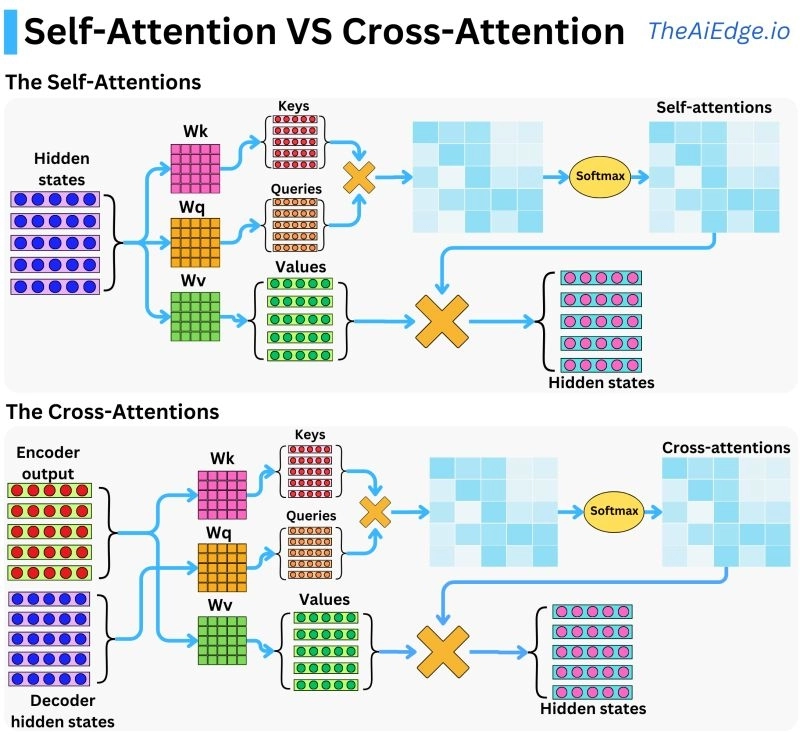
1. 입력을 학습된 변환 $W_q, W_k, W_v$에 통과시켜 Query, Key, Value 생성
2. Query × Key -> 모든 단어 쌍의 관련도 표
3. Softmax -> 각 줄 합이 1인 비율로 변환 (칸이 진할수록 많이 참고)
4. 비율 × Value -> 새로운 hidden states

#### 2. **기존 Attention in Seq2Seq (Cross-Attention)**
- Query와 Key-Value 쌍이 **서로 다른 시퀀스**에서 나옴 (Q는 디코더, K와 V는 인코더 출력)
- 디코더가 인코더에게 "지금 어디를 봐야 하지?"라고 묻는 참고 구조 (오픈북 시험처럼 답안을 쓰면서 교과서의 어디를 볼지 계속 정하는 과정)
- **핵심 과정** : 원문 "The cat is sleeping" -> 번역 중 "고양이가 ___."
  1. **Query 만들기** : 디코더가 지금까지 만든 "고양이가"를 바탕으로 현재 상태를 Query로
  2. **Key, Value 불러오기** : 인코더가 원문 각 단어(The, cat, is, sleeping)에 대해 만들어 둔 벡터
  3. **유사도 계산** : $Q \cdot K_i$ (내적) -> Softmax -> The 2%, cat 13%, is 10%, sleeping 75%
  4. **Weighted Sum** : 비율만큼 Value를 섞어 Context Vector 생성 -> 다음 단어 "자고" 출력
- 한계 : 인코더/디코더가 RNN 위에서 작동하므로 원문 내부 관계는 순서대로 읽으며 **간접적으로** 파악, 병렬 처리 불가

#### 3. **Self-Attention**
- Query와 Key-Value 쌍이 **같은 시퀀스**에서 나옴 (Q, K, V가 모두 같은 입력/hidden states에서 생성된다는 말)
- 문장이 스스로에게 "우리끼리 누가 누구와 관련이 있지?"라고 묻는 구조
  - -> **RNN 없이도 문장 내부의 관계와 문맥을 직접 파악 가능!**
- **핵심 과정** : "가을 은행 냄새 지독해"에서 '은행'의 의미 파악
  1. **벡터 임베딩** : 각 단어를 벡터로 변환하고 같은 벡터에서 Q, K, V 생성
  2. **내적 및 관련도 점수** : '은행'의 Query와 모든 단어의 Key 비교 (가로줄 = 질문하는 단어, 세로줄 = 참고 대상)
  3. **중요도 배분** : 가을 30%, 은행 20%, 냄새 45%, 지독해 5%
  4. **새로운 벡터 생성** : 비율만큼 Value를 섞어, '은행'이 "돈? 열매?"에서 **"가을에 냄새 나는 열매"** 라는 의미를 담은 새 벡터가 됨
- 이 과정을 **모든 단어가 동시에** 거쳐 각자 문맥이 반영된 새 벡터를 얻음 -> **병렬 처리 가능**

#### 4. **비교**

| 구분 | Cross-Attention | Self-Attention |
|:----:|:---------------:|:--------------:|
| 참조 대상 | 서로 다른 시퀀스 (디코더 -> 인코더) | 같은 시퀀스 (문장 내부) |
| 주요 목적 | 고정 Context Vector의 병목 해결 | 문맥이 반영된 단어 표현 생성 |
| 결과 벡터 | Context Vector | 문맥이 반영된 새 표현 |
| 기반 아키텍처 | RNN | Transformer |
| 병렬 처리 | RNN 기반일 때 불가능 | 가능 |

- <span style="color:blue">**Transformer는 두 방식을 모두 사용**</span>
  - **인코더** : Self-Attention (원문 단어끼리 관계 파악)
  - **디코더** : Self-Attention (번역 중인 문장끼리 관계 파악, 아직 안 만든 뒤쪽 단어는 못 보게 **눈가리개**)
  - **인코더-디코더 사이** : Cross-Attention (번역하면서 원문 참고)
- 즉, Seq2Seq에서 RNN이 하던 문장 내부 이해를 Self-Attention이 대신, Attention이 하던 원문 참고는 Cross-Attention이 그대로 맡음!
- 한 줄 정리 : **Cross는 "남에게 묻기", Self는 "나에게 묻기"**

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.3 Scaled Dot-Product Attention </span>

#### 1. **Dot-Product Attention**
- Query와 Key 벡터를 **내적**해 관련도 점수를 구하는 가장 기본적인 방법
  - **내적** : 두 벡터의 같은 위치 성분끼리 곱해 모두 더한 값, 방향이 비슷할수록 큰 값 (= "얼마나 닮았나"를 숫자로)
$$Q \cdot K = \sum_{i=1}^{d_k} Q_i K_i$$
- (참고) 선대 개념
  - **행렬** : 숫자를 행과 열로 배열한 것 (행 개수 × 열 개수). Attention에서는 **한 행 = 한 단어의 벡터** (ex. Q (6×3) : 단어 6개가 각각 3차원 벡터)
  - **전치(Transpose)** : 행과 열을 맞바꿈 ($A$가 $m \times n$이면 $A^T$는 $n \times m$)
  - **행렬 곱 조건** : $i \times k$ 와 $k \times j$ (앞 행렬의 열 개수 = 뒤 행렬의 행 개수), 결과는 $i \times j$
  - <span style="color:blue">**행렬 곱 = 내적의 모음** : $QK^T$의 $i$행 $j$열 값 = $i$번째 단어의 Query와 $j$번째 단어의 Key의 내적 = 두 단어의 관련도 점수</span>
    - ex. $Q$ (6×3) × $K^T$ (3×6) = (6×6) -> 그래서 $K$를 전치, 행렬 곱 한 번으로 **36개의 내적을 동시에 계산**
- **과정**
  1. **Attention Score 계산** : $Q$ (6×3)와 $K^T$ (3×6)를 곱함 -> (6×6) 점수표 (가로줄 = 질문하는 단어, 세로줄 = 참고 대상)
  2. **Softmax 적용** -> Attention Weight 산출 (**각 가로줄**을 합이 1인 비율로 전환, "이 단어는 다른 단어들을 몇 %씩 참고하는가")
  3. **최종 결과** : Attention Weight (6×6) × Value -> 각 단어가 다른 단어 정보를 비율만큼 섞은 **새 벡터 6개**

#### 2. **문제점 : Attention Score의 극단화**
- 벡터 **차원이 커질수록 내적 값이 지나치게 커짐** -> 극단적인 값이 Softmax에 들어가면 특정 단어에 확률이 과도하게 쏠림 -> 기울기가 0에 가까워져 **Vanishing Gradient** 발생

#### 3. **Scaled Dot-Product Attention**
- "Attention Is All You Need" 저자들이 제안, **Transformer의 Attention 계산 공식 그 자체**
- 내적과 Softmax 사이에 **스케일링 단계**를 추가
  1. Query와 모든 Key를 내적 -> Attention Score
  2. Attention Score를 $\sqrt{d_k}$로 **나눔** (스케일링)
  3. Softmax -> Attention Weight
  4. Attention Weight × Value -> 최종 결과
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$
- $\sqrt{d_k}$로 나누면 분산이 다시 1 근처로 돌아와, 차원 크기와 상관없이 점수가 **안정적인 범위**에 머무름
- <span style="color:green">ex. 스케일링 전에는 sheepdog 하나에 82.2%가 몰리지만, 스케일링 후 64.5%로 줄고 shetland(19.9%), affectionate(15.7%)에도 비율이 나눠져 주변 정보를 고르게 반영</span>
- **결과로 얻어지는 벡터**
  - **Cross-Attention** : Context Vector (현재 생성 중인 단어에 필요한 원문 정보를 비율만큼 모은 벡터)
  - **Self-Attention** : 문장 내 다른 단어들과의 관계가 반영되어 **의미가 업데이트된 단어 벡터**


## <span style="background-color:#fae0f0; color:#c0156d; padding:4px; border-radius:5px;"> 3. Multi-Head Attention </span>

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 3.1 왜 Multi-Head Attention을 사용할까? </span>

#### 1. **헤드(Head)란?**
- **Attention 계산을 한 번 하는 독립된 단위**
  - 자기만의 가중치 행렬 세트 $W^Q, W^K, W^V$로 Q, K, V를 만들어 Attention을 한 번 계산하고 결과 벡터 하나를 출력
  - 헤드마다 가중치 행렬의 숫자가 다르므로 **같은 문장을 봐도 집중하는 단어가 달라짐**

#### 2. **Single-Head Attention**
- 헤드 1개, 가중치 행렬 세트 하나로 512차원 벡터를 그대로 한 번 Attention -> 단어마다 **가중치 분포가 딱 하나**
- <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> 한계 : 집중력 100%를 혼자 나눠 써야 함 </span>
  - Softmax 가중치는 합이 항상 1(100%), 한 단어를 이해하려면 여러 종류의 관계가 동시에 필요한 경우가 많음 -> 100%를 여러 관계에 나눠 줄 수밖에 없고, 결과는 **여러 정보가 섞여 흐릿한 벡터**
  - <span style="color:green">ex. "Tom gave Mary a book yesterday"에서 "gave"의 가중치 : Tom 0.25, Mary 0.25, a 0.02, book 0.25, yesterday 0.23 -> 네 단어가 다 중요해 비슷하게 나눠짐 -> 준 사람이 Tom인지 Mary인지 흐려짐</span>

#### 3. **Multi-Head Attention**
- **Attention을 작게 쪼개서 여러 번 동시에 하는 방식**
  1. 512차원 벡터에 헤드마다 다른 $W^Q, W^K, W^V$를 곱해 **64차원 Q, K, V를 8세트** 생성
  2. 8개 헤드가 서로 간섭 없이 각자 Attention 계산 (가중치 분포가 8개)
  3. 8개의 64차원 결과를 **이어 붙여(Concat)** 다시 512차원으로
  4. $W^O$를 곱해 8개의 관점을 하나로 섞음
- **헤드마다 각자 100%를 씀** : 같은 예문에서 헤드 1은 Tom(Who?), 헤드 2는 Mary(To whom?), 헤드 3은 book(What?), 헤드 4는 yesterday(When?)에 각각 0.90씩 집중 -> 결과를 나란히 이어 붙이므로 **네 정보가 섞이지 않고 또렷하게 남음**
- **비유**
  - Single-Head = 기자 1명이 모든 질문을 취재해 기사 한 편 (모든 내용을 담지만 깊이가 얕음)
  - Multi-Head = 기자 8명이 각자 한 분야만 깊게 취재, 편집장($W^O$)이 8편을 엮어 한 기사로


### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 3.2 Multi-Head Attention 작동 방식 </span>
> "I love you"에서 love 한 단어가 통과하는 과정<br>
> 논문 기준 : 단어 차원 **512**, 헤드 수 **8**개, 각 헤드 차원 **64**
<br>

#### 1. **전체 흐름 4단계**
1. **분할 (Projection)** : 헤드마다 다른 $W$를 곱해 작은 Q, K, V 생성 (512 -> 64 × 8세트)
2. **병렬 어텐션 계산** : 8개 헤드가 동시에, 서로 간섭 없이 Attention 계산 (64 × 8개 결과)
3. **결합 (Concat)** : 8개 결과를 한 줄로 연결 (64 × 8 -> 512)
4. **최종 투영 (Final Projection)** : $W^O$를 곱해 8개 관점을 하나로 융합 (512 -> 512)

#### 2. **단계별 상세**
1. **분할** : love의 512차원 벡터에 헤드마다 다른 가중치 행렬을 곱해 64차원 Q, K, V를 8세트 생성 (예: 헤드 1은 love × $W_1^Q$, love × $W_1^K$, love × $W_1^V$). 다른 단어(I, you)도 똑같이 8세트씩 생성
2. **병렬 어텐션 계산** : 헤드 1 안에서
   1. **점수** : love의 $Q_1$을 I, love, you의 $K_1$과 각각 내적 -> 점수 3개
   2. **스케일** : 각 헤드 차원의 제곱근($\sqrt{64} = 8$)으로 나눔 (한 단어가 독차지하는 것을 막음)
   3. **Softmax** : 합이 1인 어텐션 가중치 (예: I 0.2, love 0.7, you 0.1)
   4. **Weighted Sum** : 이 가중치대로 I, love, you의 $V_1$을 곱해 모두 더함 -> 헤드 1의 결과 (64차원)
   - 헤드 2~8도 각자의 Q, K, V로 같은 계산을 동시에, 독립적으로 -> 64차원 결과 8개
3. **Concat** : 8개의 64차원 결과를 순서대로 이어 붙여 512차원(8×64) 벡터 하나로
4. **Final Projection** : 이어 붙인 벡터는 각 헤드 결과를 **단순 나열**한 것이므로, $W^O$ (512×512)를 곱해 8개 관점을 **하나의 의미로 융합**
- => 모든 단계가 끝나면 'love'에 대한 Multi-Head Attention 레이어의 최종 출력 벡터


## <span style="background-color:#fae0f0; color:#c0156d; padding:4px; border-radius:5px;"> 4. Transformer 전체 아키텍처 </span>
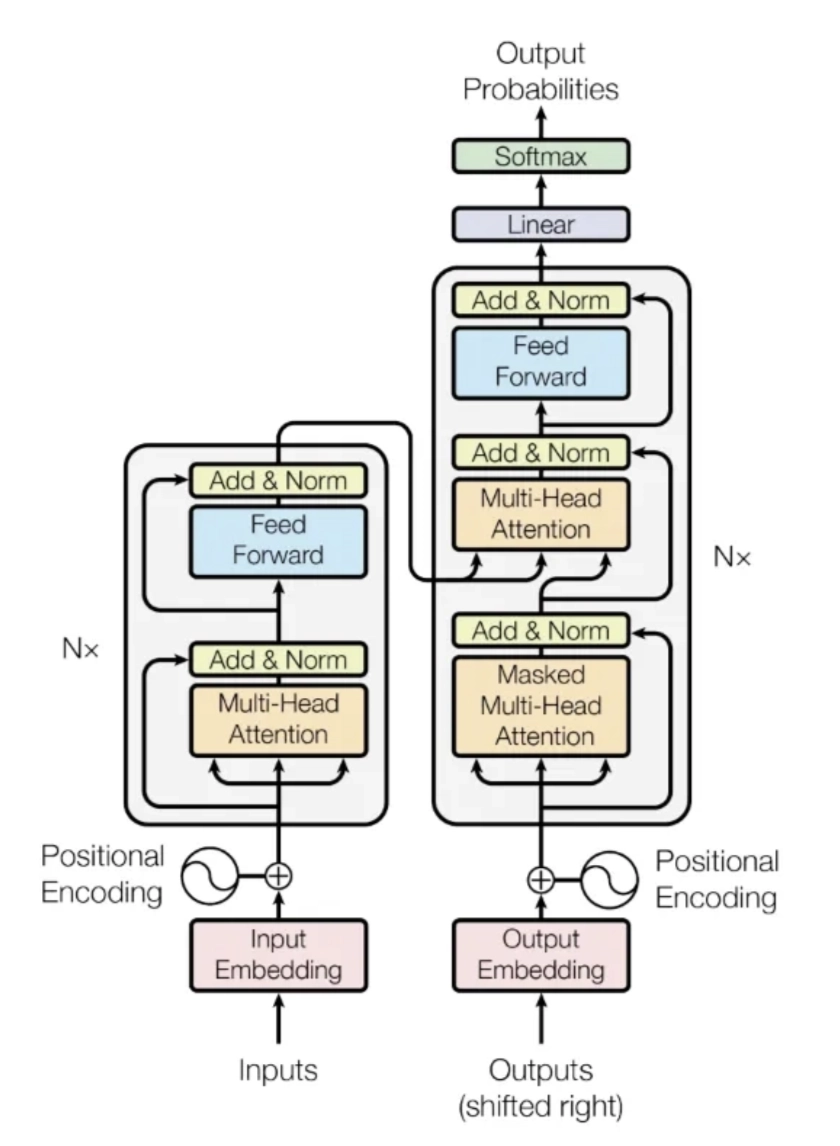

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 4.1 Transformer의 전처리 단계 </span>
- 흐름 : 텍스트 입력 -> **토큰화(Tokenization)** -> **임베딩(Embedding)** -> **Positional Encoding**

#### 1. **토큰화 (Tokenization)** : 문장을 조각내기
- 문장을 모델이 다루는 **기본 단위(토큰)** 로 자르는 것
  - 보통 단어 하나 = 토큰 하나 (Give, me, an, apple), 문장 부호도 토큰
  - 길거나 드문 단어는 여러 조각 (didn't -> did + n't)
- 비유 : 레고 블록, 자주 쓰는 조각을 미리 준비해 두면 처음 보는 단어도 조립해 표현 가능
- 논문에서는 영->독 번역에 **BPE** 방식(약 37,000개), 영->불 번역에 **word-piece** 방식(32,000개) 토큰 사전 사용

#### 2. **임베딩 (Embedding)** : 단어에 좌표 주기
- 각 토큰을 **숫자(벡터)** 로 바꾸는 것, 벡터의 길이 = 차원 ($d_{model}$, ex. 길이 1,024면 $d_{model}$도 1,024)
- **핵심 원리** : 단어를 **공간적 의미**로 표현, **뜻이 비슷한 단어는 가까운 좌표**에 놓임
  - 임베딩 값은 처음엔 무작위, 학습하며 의미에 맞는 자리를 찾아감
  - 덕분에 이후 Attention이 단어 사이의 관계를 계산할 수 있음
  - <span style="color:green">ex. 지도에서 딸기(5, 4)와 체리(6, 6)는 '과일 동네' 이웃, 성(2, 1)은 멀리 '건물 동네' (실제로는 512차원 지도)</span>
- (참고) **Word2Vec** : 단어를 벡터로 변환하는 대표적 방법
  - 신경망에 문장을 입력해 **다음에 올 단어를 예측**하도록 훈련 -> 예측을 수행하는 마지막에서 두 번째 레이어(penultimate layer)의 숫자들을 단어의 임베딩으로 사용
  - 딸기와 사과에 비슷하게 반응하고 비슷한 다음 단어를 예측하므로, 그 이전 단계의 벡터도 서로 비슷해짐

#### 3. **Positional Encoding** : 순서 번호표 붙이기
- 단어들의 **순서 정보를 임베딩 벡터에 추가**하는 단계
- **왜 필요?** : Transformer는 모든 단어를 한꺼번에 봐서, 그대로 두면 순서를 모름
  - "개는 고양이를 쫓는다"와 "고양이는 개를 쫓는다"를 구분 못하고 같은 단어 묶음으로 봄
  - RNN은 순서대로 읽어 자연스럽게 알았지만, Transformer는 **순서를 따로 알려줘야** 함
- **어떻게?** : 각 위치마다 정해진 512차원 '위치 벡터'를 만들어 임베딩에 **더함** (이어 붙이는 게 아니라 숫자끼리 더함)
  - 문장이 달라도 1번째 자리에는 항상 벡터 A, 2번째 자리에는 항상 벡터 B처럼 **규칙이 같아야** 순서를 배울 수 있음
  - 같은 단어라도 자리가 다르면 최종 벡터가 달라짐


### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 4.2 Transformer의 Encoder와 Decoder </span>

#### 1. **Encoder** : 원문을 깊이 이해하는 분석팀
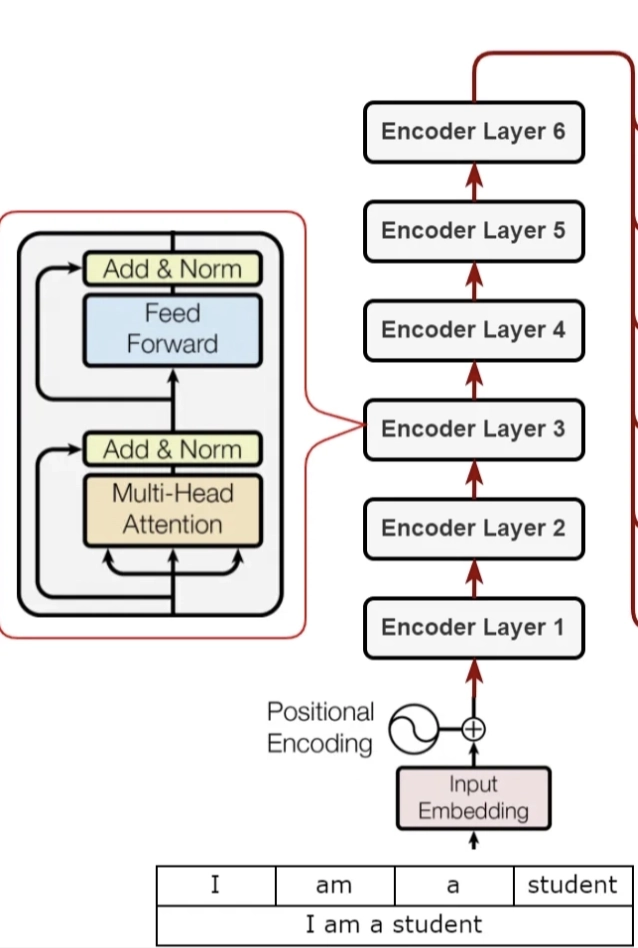
- 인코더 층 하나 = 두 부품
  1. **Multi-Head Self-Attention** : 원문 단어끼리 서로를 보며 문맥 파악
  2. **Feed-Forward Network (FFN)** : 단어 하나하나를 따로 더 깊이 가공
- **RNN/LSTM Encoder와의 차이**
  - 읽는 방식 : 단어를 하나씩 순서대로 vs **한꺼번에**
  - 정보 전달 : 이전 은닉 상태가 다음 시점으로 vs Self-Attention으로 **모든 단어가 서로 직접 연결**
  - 순서 정보 : 읽는 순서 자체에 있음 vs Positional Encoding으로 따로 넣어 줌
  - 최종 출력 : 마지막 은닉 상태 하나 vs **단어별 문맥 벡터 전부**
- **Feed-Forward Network (FFN)**
$$\text{FFN}(x) = \max(0, xW_1 + b_1)W_2 + b_2$$
  - 512차원을 2048차원으로 넓혔다가 다시 512차원으로 좁히는 **2층 신경망** (사이에 ReLU)
  - <span style="color:blue">**단어마다 따로, 같은 가중치**로 적용, 이 단계에서는 **단어끼리 정보를 주고받지 않음**</span>
  - 비유 : Self-Attention = 조별 토론(서로 의견을 들으며 생각 업데이트), FFN = 토론 후 1:1 첨삭(학생 한 명씩 같은 선생님에게 가서 노트를 다듬음)
- **Add & Norm** : 모든 부품에 붙는 안전장치
  - **Add = Residual Connection(잔차 연결)** : 부품을 통과한 결과에 **원래 입력을 그대로 더함** (CNN의 ResNet에서 온 아이디어, 원본은 두고 수정 사항만 덧붙임)
  - **Norm = Layer Normalization(층 정규화)** : 한 단어 벡터 안의 512개 숫자를 평균 0, 분산 1 근처로 맞춤 (마이크 볼륨 맞추기와 비슷, 학습을 안정적이고 빠르게)

#### 2. **Decoder** : 번역문을 한 단어씩 쓰는 작성팀
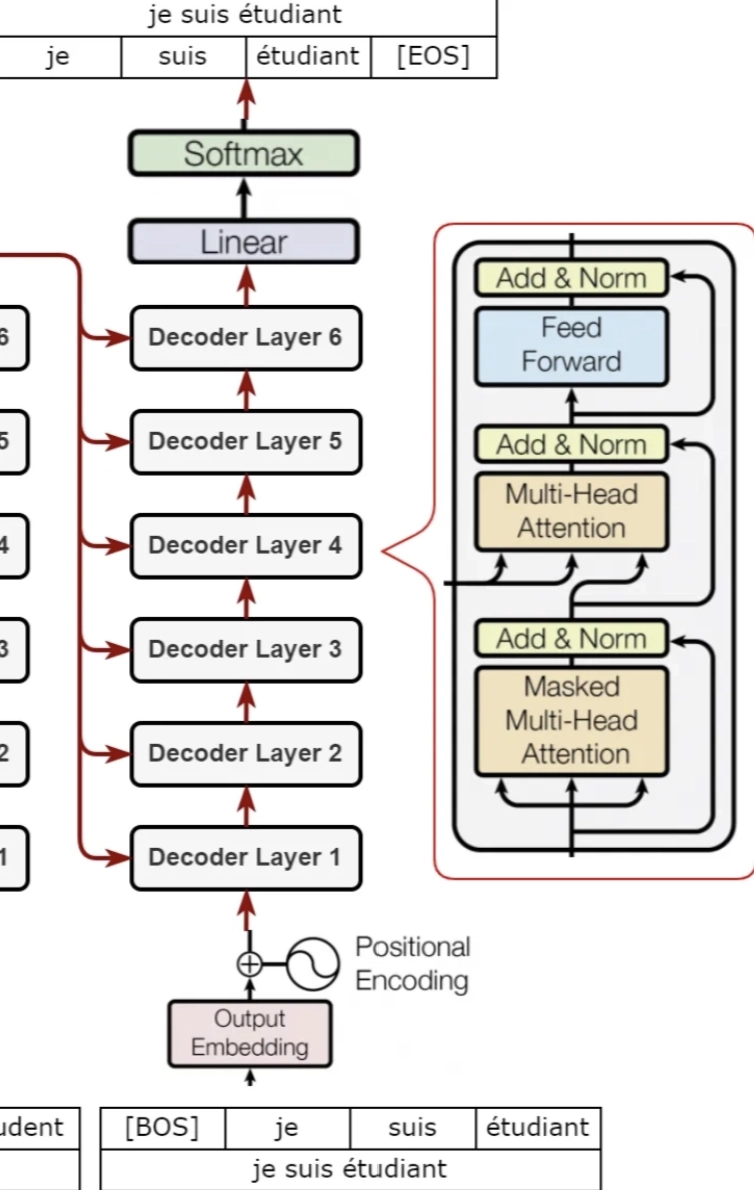
- 디코더 층 하나 = 세 부품
  1. **Masked Multi-Head Self-Attention** : 지금까지 쓴 번역 단어끼리 관계 파악 (**미래 단어는 가림**)
  2. **Encoder-Decoder Attention (Cross-Attention)** : 원문 분석 자료(Encoder 출력)에서 필요한 부분 찾기
  3. **Feed-Forward Network** : 인코더와 동일
- 세 부품 뒤에도 각각 Add & Norm, **6층**을 다 통과하면 **Linear + Softmax**가 다음 단어의 확률 계산
- **Masked Multi-Head Attention**
  - Decoder의 Self-Attention에서 **미래 시점의 단어 정보를 가려(Softmax 후 0)** 자기보다 앞의 단어만 보게 하는 메커니즘
  - <span style="color:blue">**역할** : 학습 때는 정답 문장 전체를 한 번에 넣어 병렬로 학습하는데, 마스크가 없으면 답을 미리 보고 맞히는 **"컨닝"** 이 됨</span>
  - <span style="color:green">ex. 나는 학교에 간다 -> I go to school : "I go to"를 입력받고 다음 단어를 예측할 때 뒤의 school을 미리 보면 컨닝</span>
  - 비유 : 시험 볼 때 뒤 문제의 답안을 종이로 가려두는 것
- **Encoder-Decoder Attention (Cross-Attention)**
  - 출력 문장(Decoder)과 입력 문장(Encoder)을 연결하는 과정
  - <span style="color:blue">**Q** = 직전 Decoder 서브레이어의 출력 / **K, V** = **Encoder 마지막 층**의 출력 (6개 디코더 층이 모두 같은 Encoder 출력을 씀)</span>
  - <span style="color:green">ex. Decoder가 "school"을 만들 차례 : Query = "I go to"까지의 문맥을 담은 Decoder 상태, Key/Value = "나는 학교에 간다"를 인코딩한 벡터 -> "학교" 부분에 높은 가중치</span>

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 4.3 전체 모델 및 데이터 흐름 </span>
> "I love you"를 번역하는 흐름
<br>

#### 1. **입력 준비** : 문장을 [의미 + 위치] 벡터로
- **임베딩** : I, love, you를 각각 의미 벡터로 변환
- **Positional Encoding** : 0, 1, 2번 위치 벡터를 더함 -> "love"는 "2번째 자리의 love"가 됨

#### 2. **인코더** : 입력 문장의 문맥적 의미를 깊이 이해
- 6개 레이어를 통과하며 Multi-Head Self-Attention으로 "love"가 주어 "I", 목적어 "you"와의 관계를 흡수하고, FFN으로 다듬음
- **인코더 레이어 1개 안의 순서**
  1. Multi-Head Self-Attention (단어들이 서로를 참조해 문맥을 섞음)
  2. Add & Norm (입력을 다시 더하고 정규화)
  3. Feed-Forward (512 -> 2048 -> 512, 각 단어 벡터를 따로 가공)
  4. Add & Norm
- 출력 : 문맥적 의미를 담은 벡터 -> **Decoder의 K, V로 전달**

#### 3. **디코더** : 번역 문장을 한 단어씩 생성
- 시작 토큰으로 시작 -> Masked Self-Attention(지금까지 만든 단어만) -> Cross-Attention(Encoder 출력 참조) -> FFN, 이를 **6층 반복**
- 선형 + Softmax로 어휘 전체의 확률을 구해 가장 높은 단어 출력
- **단계별 진행**
  - Step 1 : `<start>`만 볼 수 있음 / 원문에서 "첫 단어로 뭐가 중요하지?" -> **I**에 집중 -> **"나는"** 출력
  - Step 2 : `<start> 나는` / "다음엔 뭐가 중요하지?" -> **you**에 집중 -> **"당신을"** 출력
  - Step 3 : `<start> 나는 당신을` / "이제 남은 건?" -> **love**에 집중 -> **"사랑해"** 출력
  - Step 4 : 문장이 완성됐다는 문맥 파악, 원문에서 더 옮길 내용 없음 -> `<end>` 출력 -> **종료**
- 결과 : "나는 당신을 사랑해"~~